In [1]:
from SymbolicDSGE import parse_config, solve_model, Estimator, LinearKalman
from SymbolicDSGE.utils import FRED
from SymbolicDSGE.utils.math_utils import HP_two_sided, annualized_log_percent
from SymbolicDSGE.estimation import make_prior

from sympy import Matrix
from warnings import catch_warnings, simplefilter

import numpy as np

import pandas as pd

In [2]:
model = parse_config("../../MODELS/POST82.yaml")

with catch_warnings():
    # Equations in a sp.Matrix are deprecated, this is only used as a pretty print function
    simplefilter(action="ignore")
    mat = Matrix(list(model.equations.model.values()))
mat

Matrix([
[                                  Eq(Pi(t), beta*Pi(t + 1) + kappa*(x(t) - z(t)))],
[                         Eq(x(t), -tau_inv*(-Pi(t + 1) + r(t)) + g(t) + x(t + 1))],
[Eq(r(t), e_r + rho_r*r(t - 1) + (1 - rho_r)*(psi_pi*Pi(t) + psi_x*(x(t) - z(t))))],
[                                                   Eq(g(t), e_g + rho_g*g(t - 1))],
[                                                   Eq(z(t), e_z + rho_z*z(t - 1))]])

In [3]:
fred = FRED(
    key_env=None,  # None => look for the ".env" file. If you have a custom env file, provide its path here.
    key_name="FRED_KEY",  # Name of the variable in the env file that contains the FRED API key.
)
df = fred.get_frame(
    series_ids=[
        "GDPC1",  # Real GDP
        "CPIAUCSL",  # Consumer Price Index for All Urban Consumers: All Items
        "FEDFUNDS",  # Effective Federal Funds Rate
    ],
    date_range=(
        "1955-01-01",
        "2007-10-01",
    ),  # Date range for the data ("YYYY-MM-DD" format or a pd.DatetimeIndex object)
)

gdp_q = df["GDPC1"]  # already quarterly in most pulls; verify freq

cpi_q = df["CPIAUCSL"].resample("QS").mean()  # quarterly avg CPI
ffr_q = df["FEDFUNDS"].resample("QS").mean()  # quarterly avg policy rate

idx_range = pd.date_range(start="1984-01-01", end="2007-01-01", freq="QS")


df = pd.DataFrame(
    {
        "GDPC1": gdp_q.reindex(idx_range),
        "CPIAUCSL": cpi_q.reindex(idx_range),
        "FEDFUNDS": ffr_q.reindex(idx_range),
    }
)

df

,GDPC1,CPIAUCSL,FEDFUNDS
1984-01-01,8034.847,102.533333,9.686667
1984-04-01,8173.670,103.500000,10.556667
1984-07-01,8252.465,104.400000,11.390000
1984-10-01,8320.199,105.300000,9.266667
1985-01-01,8400.820,106.266667,8.476667
...,...,...,...
2006-01-01,16353.835,199.466667,4.456667
2006-04-01,16396.151,201.266667,4.906667
2006-07-01,16420.738,203.166667,5.246667
2006-10-01,16561.866,202.333333,5.246667


In [4]:
x_trend = HP_two_sided(np.log(df["GDPC1"]), lamb=1600)[0]  # returns (trend, cycle)
x = (np.log(df["GDPC1"]) - x_trend) * 100  # HP detrended quarterly log output gap


inf_lvl = annualized_log_percent(df["CPIAUCSL"], periods_per_year=4)
rate_lvl = df["FEDFUNDS"]

r_ss = model.calibration.parameters["r_star"]
pi_ss = model.calibration.parameters["pi_star"]

rate = (rate_lvl - (r_ss + pi_ss)) / 4  # gap to steady state
inf = (inf_lvl - pi_ss) / 4  # gap to steady state

df_model_units = pd.DataFrame(
    {
        "r": rate,
        "Pi": inf,
        "x": x,
    }
).dropna()

observed = pd.DataFrame(
    {
        "Infl": inf_lvl[df_model_units.index],
        "Rate": rate_lvl[df_model_units.index],
    }
)
observed.index = df_model_units.index

In [9]:
estimated = {
    # (0, 1)
    "beta": make_prior(
        "beta",
        parameters={"a": 200 * 0.971, "b": 200 * 0.029},
        transform="logit",
    ),
    "rho_r": make_prior(
        "beta",
        parameters={"a": 200 * 0.84, "b": 200 * 0.16},
        transform="logit",
    ),
    "rho_g": make_prior(
        "beta",
        parameters={"a": 200 * 0.83, "b": 200 * 0.17},
        transform="logit",
    ),
    "rho_z": make_prior(
        "beta",
        parameters={"a": 200 * 0.85, "b": 200 * 0.15},
        transform="logit",
    ),
    # (0, +inf)
    "psi_pi": make_prior(
        "gamma",
        parameters={"mean": 2.19, "std": 0.5},
        transform="log",
    ),
    "psi_x": make_prior(
        "gamma",
        parameters={"mean": 0.30, "std": 0.1},
        transform="log",
    ),
    "kappa": make_prior(
        "gamma",
        parameters={"mean": 0.58, "std": 0.1},
        transform="log",
    ),
    "tau_inv": make_prior(
        "gamma",
        parameters={"mean": 1.86, "std": 0.5},
        transform="log",
    ),
    # Correlation (-1,1)
    "Q_corr": make_prior(
        "lkj_chol",
        transform="cholesky_corr",
        parameters={"eta": 2.0, "K": 3},
    ),
    "R_corr": make_prior(
        "lkj_chol",
        transform="cholesky_corr",
        parameters={"eta": 2.0, "K": 2},
    ),
    # Shock std devs (0, +inf)
    "sig_r": make_prior(
        "gamma",
        parameters={"mean": 0.18, "std": 0.1},
        transform="log",
    ),
    "sig_g": make_prior(
        "gamma",
        parameters={"mean": 0.18, "std": 0.1},
        transform="log",
    ),
    "sig_z": make_prior(
        "gamma",
        parameters={"mean": 0.64, "std": 0.1},
        transform="log",
    ),
    "meas_infl": make_prior(
        "normal",
        parameters={"mean": 0.0, "std": 0.4},
        transform="log",
    ),
    "meas_rate": make_prior(
        "normal",
        parameters={"mean": 0.0, "std": 0.4},
        transform="log",
    ),
}

est = Estimator(
    config=model,
    filter=LinearKalman(jitter=1e-8),
    y=observed.loc[observed.index >= "1984-01-01", :],
    observables=["Infl", "Rate"],
    estimated_params=estimated,
    ss_seed=[0.0, 0.0, 0.0, 0.0, 0.0],
)
res = est.mcmc(
    n_draws=100_000,
    burn_in=10_000,
    thin=1,
    random_state=0,
)

MCMC sampling concluded in 5.78 seconds with 19034.66 iterations per second.
[Estimator:mcmc] BK stability warnings encountered during search: 0


In [10]:
point = res.posterior_point("mean", digits=3)
ess = res.ess
ess_ps = res.ess_per_second
mcse = res.mcse
hpd = res.hpd_intervals(alpha=0.05, digits=3)

# Summary containing above statistics
print(res.summary(alpha=0.05, digits=3))

              mean    std       ess  ess_per_second   mcse    hpd (α=0.050)
beta         0.970  0.012  1080.967         207.389  0.000   (0.946, 0.991)
rho_r        0.821  0.024   609.138         116.866  0.001   (0.775, 0.867)
rho_g        0.879  0.022   773.301         148.362  0.001    (0.837, 0.92)
rho_z        0.857  0.027   849.216         162.926  0.001   (0.801, 0.903)
psi_pi       3.128  0.514   748.098         143.526  0.019    (2.14, 4.165)
psi_x        0.335  0.107  1129.950         216.787  0.003   (0.147, 0.549)
kappa        0.476  0.091   962.888         184.735  0.003     (0.31, 0.66)
tau_inv      1.158  0.373   611.130         117.248  0.015   (0.497, 1.915)
rho_gz       0.095  0.433   851.210         163.309  0.015  (-0.694, 0.871)
rho_gr      -0.089  0.351   787.469         151.080  0.013  (-0.751, 0.558)
rho_zr       0.093  0.390  1232.485         236.458  0.011  (-0.636, 0.815)
meas_rho_ir -0.124  0.429  1155.332         221.656  0.013  (-0.886, 0.672)
sig_r       

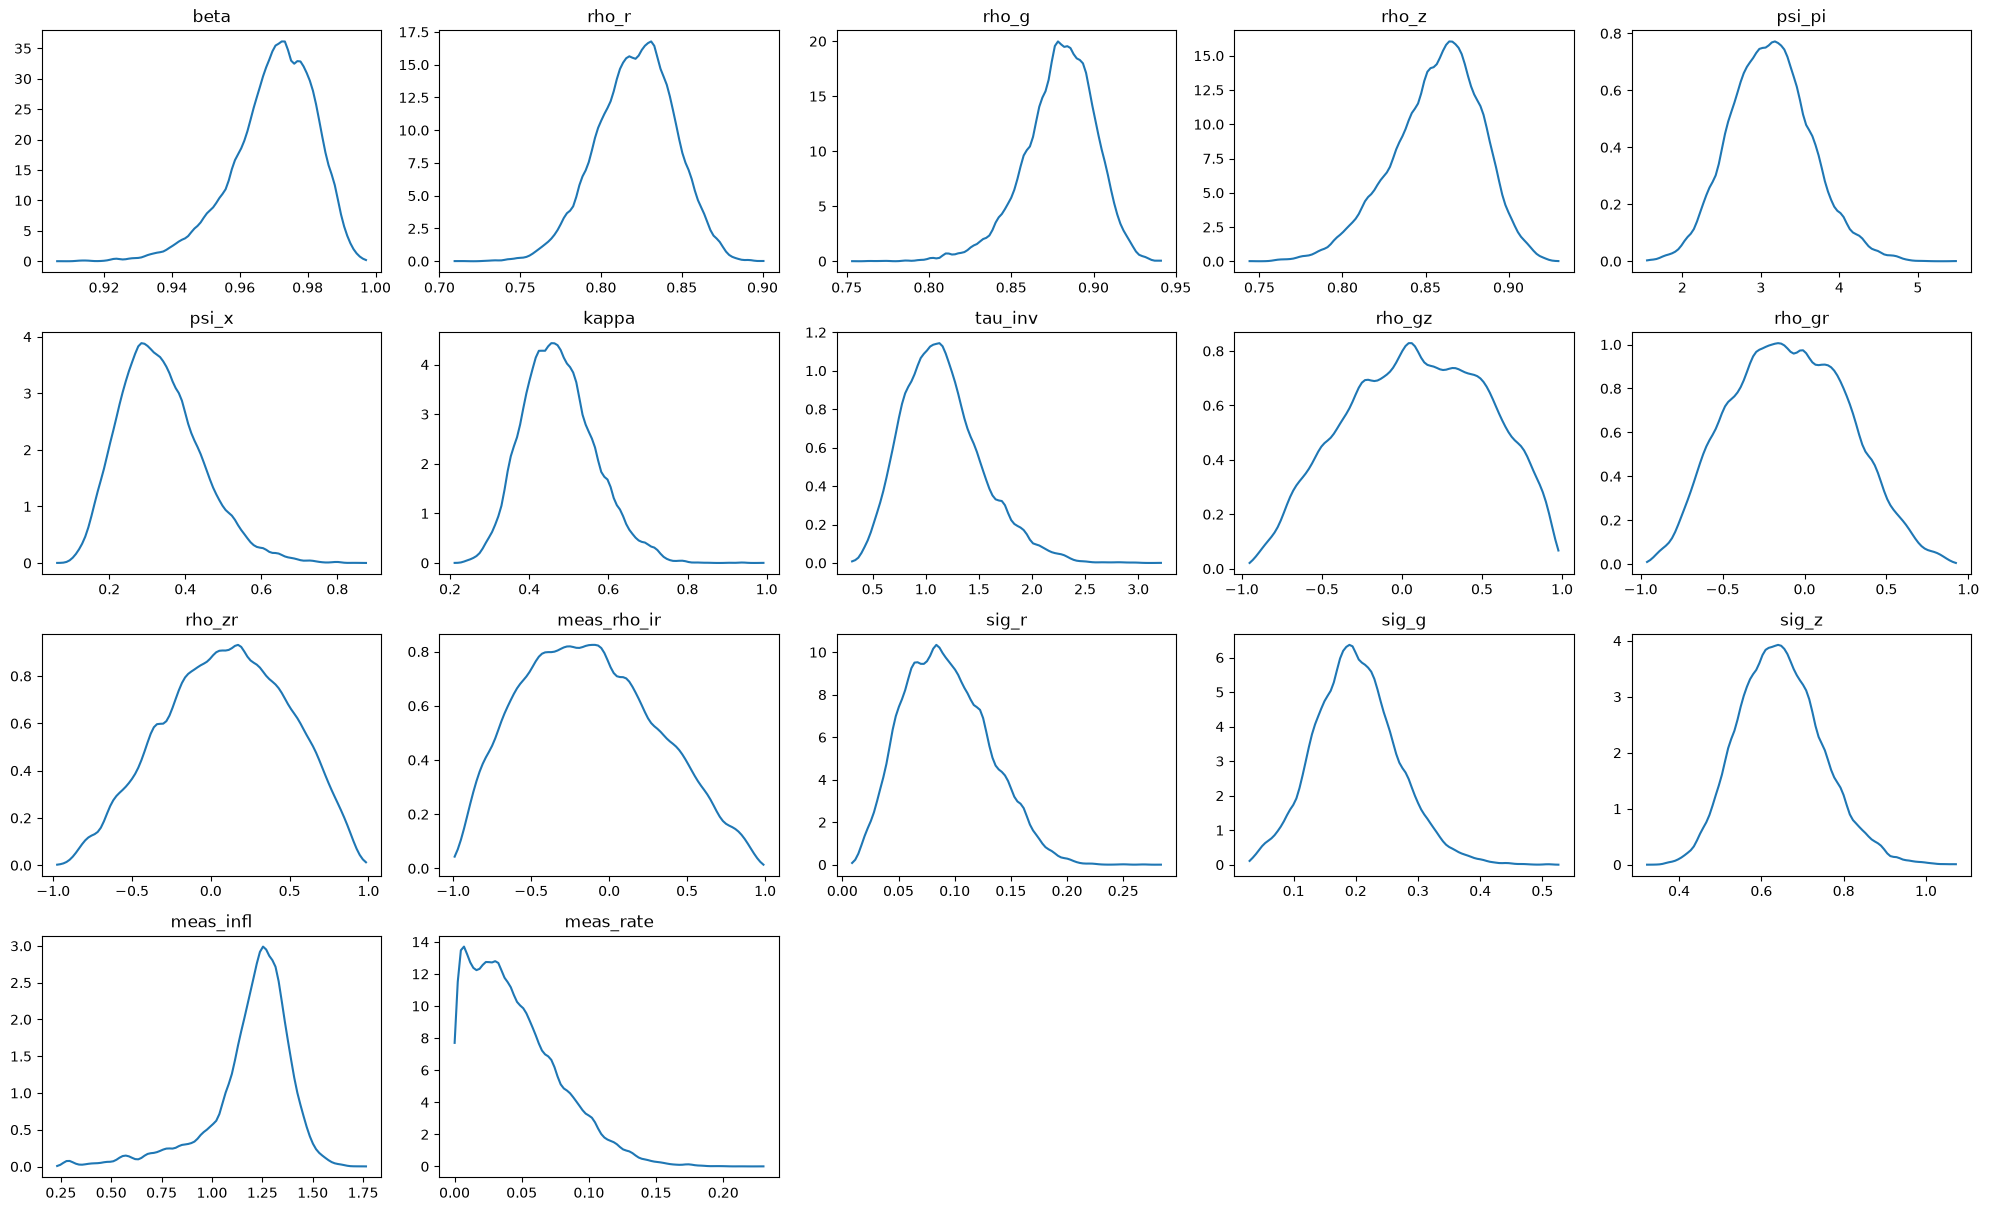

In [11]:
res.posterior_kde_plot(grid_points=100)

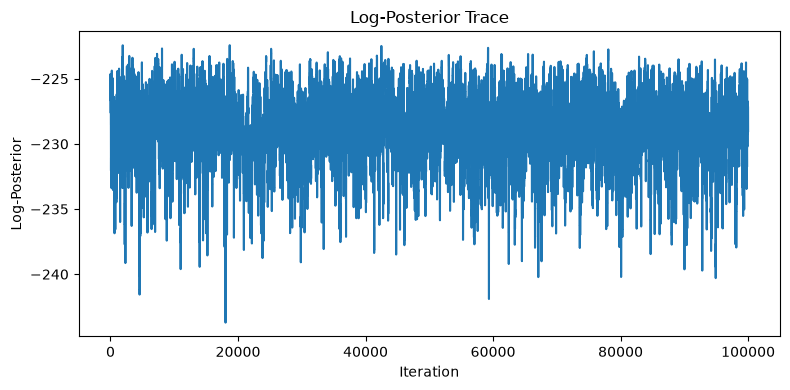

In [12]:
res.logpost_trace_plot()

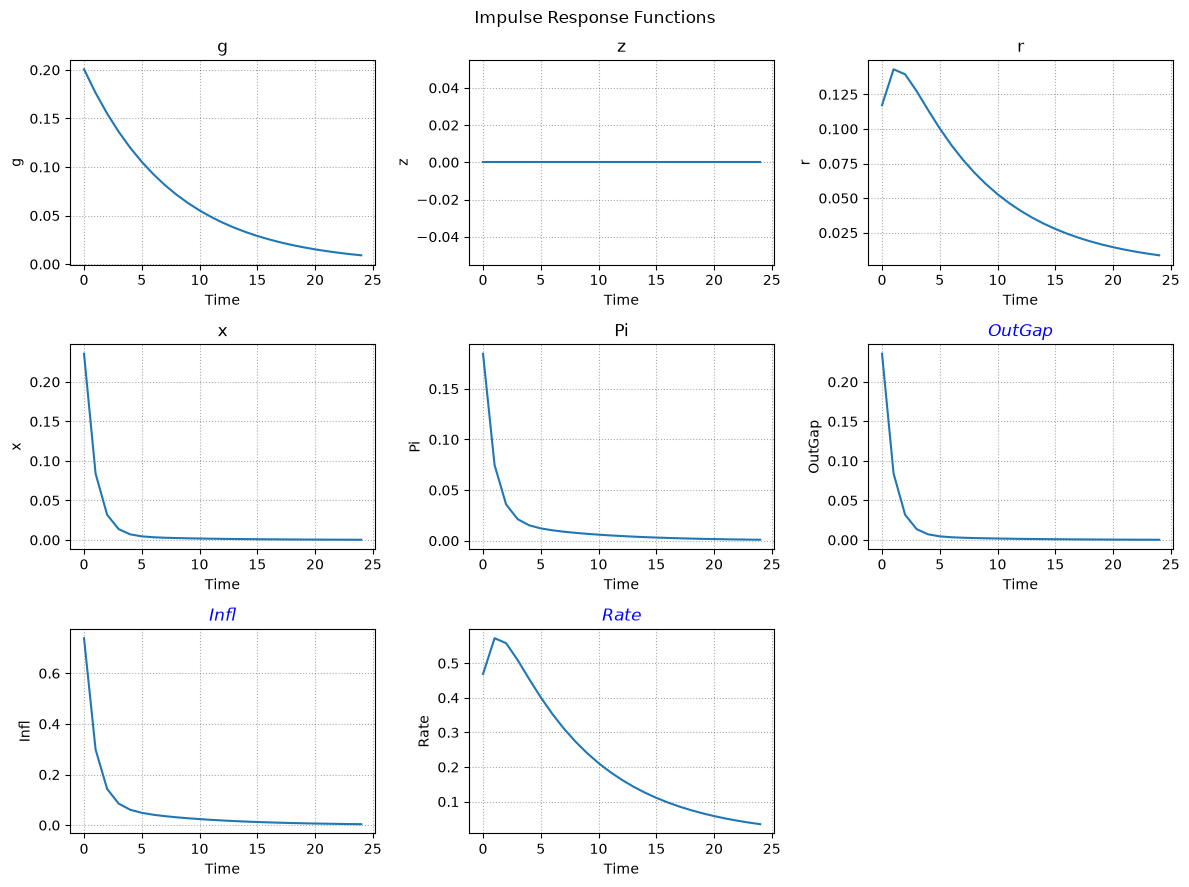

In [13]:
estimated = res.apply_to(model)
sol = solve_model(estimated)
sol.transition_plot(shocks=["e_g"], T=25, scale=1, observables=True)